# 70. 튜닝: 취약 지수 파라미터 스윕, 예측·분류 모델 하이퍼파라미터, 손실 직접 예측 모델

회의 요청(2026-10-11): "지수 세부 파라미터·가중치를 다양하게 돌려보고 확정", "매출 손실 예측 모델".

1. 취약 지수 파라미터 스윕: 가중치 × 결합 방식 × 윈저화 × 증거 규칙 × 등급 컷 = 216가지 설정으로 지수를 다시 만들어, 설정에 따라 순위와 취약 집합이 얼마나 흔들리는지와 "어떤 설정에서도 취약인 업종"(합의 목록)을 본다.
2. 일 매출 예측 모델(LightGBM) 하이퍼파라미터 무작위 탐색(월 단위 교차검증) + Ridge 기준선 + 지역별 분리 모델.
3. 이벤트일 경보 분류 모델 하이퍼파라미터 탐색 + 로지스틱 기준선 + 확률 보정 + 비용 기준 임계값.
4. 손실 직접 예측 모델: 이벤트일의 기준선 대비 감소율을 업종 구조 × 이벤트 강도로 직접 예측하고, 회귀 민감도 방식과 비교.

입력: 20·30번 표, `vulnerability.py`, `models.py`. 출력: `outputs/tables/t_*.csv`, `t_best_params.json`, 그림 `t*.png`

In [1]:
import itertools
import json
import sys
import time
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import spearmanr
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import mean_absolute_error, roc_auc_score, average_precision_score
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline

sys.path.insert(0, str(Path.cwd()))
from common import FIG, TAB, REGIONS, REGION_NAME, FACE_GROUPS, load
from analysis import RC, SURFACE, INK, INK2, MUTED, GRID, AXIS, WASH, REGION_COLOR, finish
import vulnerability as vul
import models as M

FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
plt.rcParams.update(RC)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_rows", 120)
rng = np.random.default_rng(42)

## 1. 취약 지수 파라미터 스윕

먼저 기본 설정이 30번 결과와 같은지 확인한 뒤, 216가지 설정을 돌린다.

In [2]:
inputs = vul.load_inputs()
base = vul.build_index(vul.DEFAULT, inputs)
v30 = pd.read_csv(TAB / "v_index.csv", encoding="utf-8-sig").set_index(["region", "industry"])
chk = base[["V", "loss_total"]].join(v30[["V", "loss_total"]], rsuffix="_30")
print("30번과 비교: V 최대 차이", float((chk.V - chk.V_30).abs().max()), "| 손실 최대 차이(원)", float((chk.loss_total - chk.loss_total_30).abs().max()),
      "| 등급 일치", (base.grade_V == v30.grade_V.reindex(base.index)).mean())
sb_idx = base.index[base.sb == 1]
WEIGHTS = {"0.5/0.25/0.25(기본)": (0.5, 0.25, 0.25), "균등": (1/3, 1/3, 1/3), "0.6/0.2/0.2": (0.6, 0.2, 0.2), "0.4/0.3/0.3": (0.4, 0.3, 0.3),
           "0.7/0.15/0.15": (0.7, 0.15, 0.15), "민감도만": (1.0, 0.0, 0.0)}
GRID = list(itertools.product(WEIGHTS.items(), [True, False], [0.95, 1.0], [0.05, 0.10, None], [(0.75, 0.90), (0.70, 0.90), (0.80, 0.95)]))
print("설정 수", len(GRID))
rows, members, very = [], {}, {}
t0 = time.time()
base_vuln = set(base.index[(base.sb == 1) & base.grade_V.isin(["취약", "매우 취약"])])
for (wname, (ws, we, wa)), geo, win, ep, (cv, cvy) in GRID:
    params = dict(w_s=ws, w_e=we, w_a=wa, geometric=geo, winsor=win, evid_p=ep, cut_vuln=cv, cut_very=cvy)
    r = vul.build_index(params, inputs)
    s = r.loc[sb_idx]
    vuln = set(s.index[s.grade_V.isin(["취약", "매우 취약"])]); vv = set(s.index[s.grade_V == "매우 취약"])
    key = (wname, "기하" if geo else "산술", win, ep if ep is not None else "없음", f"{int(cv*100)}/{int(cvy*100)}")
    members[key] = vuln; very[key] = vv
    rows.append({"가중치": wname, "결합": "기하" if geo else "산술", "윈저화": win, "증거 규칙 p": ep if ep is not None else "없음", "등급 컷(%)": f"{int(cv*100)}/{int(cvy*100)}",
                 "순위 상관(기본 대비)": spearmanr(s.V, base.loc[sb_idx, "V"]).correlation, "취약 수": len(vuln),
                 "취약 집합 자카드(기본 대비)": len(vuln & base_vuln) / len(vuln | base_vuln) if (vuln | base_vuln) else 1.0,
                 "손실 합계(억)": s.loss_total.sum() / 1e8, "춘천 손실(억)": s.loc["chuncheon"].loss_total.sum() / 1e8, "강남 손실(억)": s.loc["gangnam"].loss_total.sum() / 1e8})
sweep = pd.DataFrame(rows)
sweep.round(3).to_csv(TAB / "t_index_sweep.csv", index=False, encoding="utf-8-sig")
print(f"{time.time() - t0:.0f}초")
print("설정별 요약(평균):"); sweep.groupby(["가중치"])[["순위 상관(기본 대비)", "취약 집합 자카드(기본 대비)", "취약 수"]].mean().round(3)

30번과 비교: V 최대 차이 4.980349944322393e-05 | 손실 최대 차이(원) 4.971027374267578e-05 | 등급 일치 1.0
설정 수 216


17초
설정별 요약(평균):


,순위 상관(기본 대비),취약 집합 자카드(기본 대비),취약 수
가중치,,,
0.4/0.3/0.3,0.733,0.547,21.0
0.5/0.25/0.25(기본),0.777,0.595,21.0
0.6/0.2/0.2,0.806,0.629,21.0
0.7/0.15/0.15,0.828,0.644,21.0
균등,0.701,0.508,21.0
민감도만,0.832,0.624,21.0


In [3]:
summ = {}
for col in ["결합", "윈저화", "증거 규칙 p", "등급 컷(%)", "가중치"]:
    summ[col] = sweep.groupby(col)[["순위 상관(기본 대비)", "취약 집합 자카드(기본 대비)", "취약 수", "손실 합계(억)"]].mean().round(3)
pd.concat(summ, names=["설정 축", "값"])

순위 상관(기본 대비)  취약 집합 자카드(기본 대비)  취약 수  손실 합계(억)
설정 축    값                                                                
결합      기하                        0.808             0.622  21.0   342.164
        산술                        0.751             0.560  21.0   342.164
윈저화     0.95                      0.819             0.616  21.0   342.164
        1.0                       0.740             0.567  21.0   342.164
증거 규칙 p 0.05                      0.808             0.671  21.0   298.981
        0.1                       0.901             0.750  21.0   300.394
        없음                        0.630             0.352  21.0   427.117
등급 컷(%) 70/90                     0.780             0.602  25.0   342.164
        75/90                     0.780             0.618  21.0   342.164
        80/95                     0.780             0.553  17.0   342.164
가중치     0.4/0.3/0.3               0.733             0.547  21.0   342.164
        0.5/0.25/0.25(기본)         0.777             0.595  21.0   342.164
        0.6/0.2/0.2               0.806             0.629  21.0   342.164
        0.7/0.15/0.15             0.828             0.644  21.0   342.164
        균등                        0.701             0.508  21.0   342.164
        민감도만                      0.832             0.624  21.0   342.164

### 합의 목록: 설정을 바꿔도 취약으로 남는 업종

216가지 설정 중 몇 %에서 취약(취약+매우 취약)으로 분류됐는지. 80% 이상이면 "설정과 무관하게 취약", 20% 미만이면 "설정에 따라 흔들림".

In [4]:
freq = pd.Series([np.mean([ind in m for m in members.values()]) for ind in sb_idx], index=sb_idx, name="취약 빈도")
freq_v = pd.Series([np.mean([ind in m for m in very.values()]) for ind in sb_idx], index=sb_idx, name="매우 취약 빈도")
cons = pd.concat([freq, freq_v, base.loc[sb_idx, ["group", "S_rain_biz10", "S_tropical", "V", "grade_V", "loss_total"]]], axis=1)
cons["손실(억)"] = (cons.loss_total / 1e8).round(2)
cons["판정"] = np.select([cons["취약 빈도"] >= 0.8, cons["취약 빈도"] >= 0.5, cons["취약 빈도"] >= 0.2], ["확정 취약", "다수 취약", "경계"], "보통")
cons = cons.sort_values("취약 빈도", ascending=False)
cons.round(3).drop(columns="loss_total").to_csv(TAB / "t_index_consensus.csv", encoding="utf-8-sig")
print(cons.groupby(["판정"]).size())
cons[cons["취약 빈도"] >= 0.2].drop(columns="loss_total").round(2)

판정
경계       13
다수 취약    13
보통       49
확정 취약     7
dtype: int64


취약 빈도  매우 취약 빈도    group  S_rain_biz10  S_tropical     V grade_V  손실(억)     판정
region    industry                                                                                      
chuncheon 시계/귀금속           1.00      0.73    패션·잡화         17.73        0.00  0.23      취약   0.93  확정 취약
          화원               0.97      0.75  생활·기타소매         29.97        0.00  0.29   매우 취약   0.97  확정 취약
          가구               0.94      0.72  생활·기타소매         28.97        0.00  0.27   매우 취약   1.43  확정 취약
          세탁소              0.93      0.69    개인서비스         27.77        0.00  0.25   매우 취약   0.86  확정 취약
          중고품판매점           0.92      0.64  생활·기타소매         28.90        0.00  0.26   매우 취약   0.16  확정 취약
          인테리어/건축자재/주방기구   0.87      0.48  생활·기타소매         18.21        0.00  0.26   매우 취약   3.39  확정 취약
          애완동물             0.81      0.31  생활·기타소매         18.19        0.00  0.26   매우 취약   0.75  확정 취약
          농수산물             0.77      0.18   식품·생필품         14.54        0.00  0.24      취약   2.28  다수 취약
gangnam   기타식품             0.77      0.00   식품·생필품         13.79        0.00  0.22      취약   7.98  다수 취약
chuncheon 일식               0.75      0.15      음식점         18.66        0.00  0.25      취약   3.19  다수 취약
          완구/아동용자전거        0.67      0.26  생활·기타소매         20.67        0.00  0.25   매우 취약   0.42  다수 취약
gangnam   싸우나/목욕탕          0.67      0.42    개인서비스          1.42        5.02  0.32   매우 취약   0.71  다수 취약
          화원               0.67      0.53  생활·기타소매          3.36        4.44  0.35   매우 취약   0.86  다수 취약
chuncheon 의복/의류            0.65      0.01    패션·잡화         16.05        0.00  0.22      취약   2.77  다수 취약
gangnam   인테리어/건축자재/주방기구   0.65      0.02  생활·기타소매         11.42        0.00  0.22      취약   3.28  다수 취약
chuncheon 유흥업소             0.64      0.51    주점·유흥          8.76        0.00  0.11      보통   1.70  다수 취약
          생활잡화/수입상품점       0.62      0.00  생활·기타소매         16.57        0.00  0.23      취약   2.55  다수 취약
gangnam   세탁소              0.61      0.15    개인서비스         12.12        0.00  0.21      취약   0.91  다수 취약
chuncheon 서점               0.57      0.00  생활·기타소매         15.71        0.00  0.23      취약   0.47  다수 취약
          안마/마사지           0.53      0.00    개인서비스         14.53        0.00  0.22      취약   0.14  다수 취약
          커피전문점            0.48      0.00  카페·베이커리         15.56        0.00  0.23      취약   2.88     경계
          모텔,여관,기타숙박       0.45      0.10       숙박         11.21        0.00  0.20      보통   0.65     경계
          한식               0.43      0.02      음식점         11.87        0.00  0.20      보통  31.89     경계
          사무기기/문구용품        0.38      0.15  생활·기타소매         12.88        0.00  0.20      보통   0.27     경계
          양식               0.35      0.00      음식점         11.81        0.00  0.20      보통   1.85     경계
gangnam   기타요식             0.35      0.25      음식점         11.24        0.00  0.19      보통  41.85     경계
          문화용품             0.33      0.06  생활·기타소매          8.93        0.00  0.18      보통   0.77     경계
          사무기기/문구용품        0.33      0.26  생활·기타소매          7.59        0.00  0.17      보통   0.96     경계
          미용실              0.32      0.11    개인서비스          8.01        0.00  0.16      보통  10.66     경계
chuncheon 패션잡화             0.32      0.00    패션·잡화         15.84        0.00  0.21      취약   1.74     경계
gangnam   화장품              0.27      0.00    패션·잡화          3.08        0.00  0.11      보통   2.28     경계
          한식               0.23      0.01      음식점          4.18        0.00  0.11      보통  25.11     경계
chuncheon 기타식품             0.22      0.16   식품·생필품          6.07        0.00  0.15      보통   3.73     경계

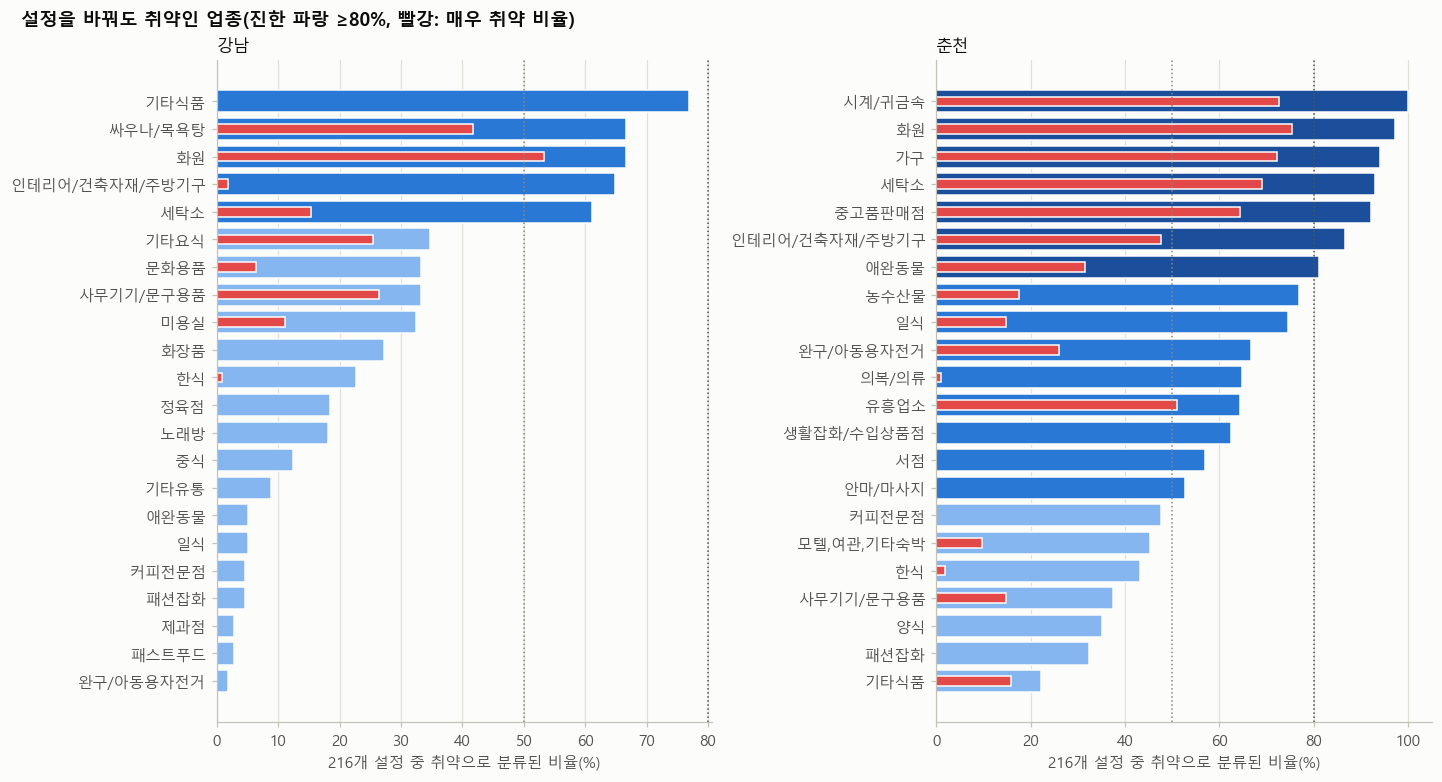

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 7), layout="constrained")
for ax, r in zip(axes, REGIONS):
    x = cons.xs(r, level="region")
    x = x[x["취약 빈도"] > 0].sort_values("취약 빈도", ascending=True).tail(22)
    colors = ["#1b4f9c" if v >= 0.8 else ("#2a78d6" if v >= 0.5 else "#86b6ef") for v in x["취약 빈도"]]
    ax.barh(range(len(x)), x["취약 빈도"] * 100, color=colors, edgecolor=SURFACE)
    ax.barh(range(len(x)), x["매우 취약 빈도"] * 100, color="#e34948", edgecolor=SURFACE, height=0.35)
    ax.set_yticks(range(len(x)), x.index); ax.set_xlabel("216개 설정 중 취약으로 분류된 비율(%)"); ax.set_title(REGION_NAME[r]); ax.grid(axis="y", visible=False)
    ax.axvline(80, color=INK2, lw=1, ls=":"); ax.axvline(50, color=MUTED, lw=1, ls=":")
finish(fig, FIG, "t01_index_consensus", "설정을 바꿔도 취약인 업종(진한 파랑 ≥80%, 빨강: 매우 취약 비율)")
plt.show()

### 확정안

기본 설정(0.5/0.25/0.25, 기하평균, 윈저화 95%, 증거 규칙 p<0.10, 상위 25%/10%)을 유지하되, 보고서에는 "합의 목록"(≥80%)을 취약 상권으로 쓰고 50~80%는 "경계"로 표기하는 것을 제안한다. 아래는 축별로 결과를 가장 많이 흔드는 요인.

In [6]:
axis_effect = {}
for col in ["가중치", "결합", "윈저화", "증거 규칙 p", "등급 컷(%)"]:
    g = sweep.groupby(col)["취약 집합 자카드(기본 대비)"].mean()
    axis_effect[col] = {"최소": g.min(), "최대": g.max(), "범위": g.max() - g.min(), "가장 흔드는 값": g.idxmin()}
pd.DataFrame(axis_effect).T.round(3).sort_values("범위", ascending=False)

,최소,최대,범위,가장 흔드는 값
증거 규칙 p,0.35154,0.750467,0.398927,없음
가중치,0.50827,0.643968,0.135698,균등
등급 컷(%),0.552864,0.618409,0.065545,80/95
결합,0.560176,0.622093,0.061917,산술
윈저화,0.566688,0.615581,0.048892,1.0


## 2. 일 매출 예측 모델 튜닝

40번과 같은 데이터·검증(월 단위 교차검증). 하이퍼파라미터 30개 조합을 무작위로 뽑아 평가하고, Ridge 기준선과 지역별 분리 모델도 비교한다. 선택 기준은 전체 MAE(log)이고 비 온 날 WAPE·편향을 같이 본다.

In [7]:
d = M.load_daily()
dm = d.dropna(subset=["r"]).copy()
print(f"행 {len(dm):,}, 시리즈 {dm.series.nunique()}")
space = dict(num_leaves=[7, 15, 31, 63], learning_rate=[0.02, 0.03, 0.05, 0.08], n_estimators=[200, 400, 700, 1000], min_child_samples=[20, 50, 100, 200],
             colsample_bytree=[0.5, 0.7, 0.9], subsample=[0.7, 0.9], reg_lambda=[0.0, 2.0, 10.0, 30.0], min_split_gain=[0.0, 0.01])
def sample(n):
    out = []
    for _ in range(n):
        out.append({k: v[rng.integers(len(v))] for k, v in space.items()})
    return out
configs = [dict(M.REG_PARAMS)] + [{**M.REG_PARAMS, **c} for c in sample(30)]
rows = []
t0 = time.time()
for i, cfg in enumerate(configs):
    cfg = {**cfg, "subsample_freq": 1, "random_state": 42, "verbose": -1}
    r = M.cv_month(dm, M.FEAT_FULL, cfg)
    mt = M.metrics(r, "pred")
    rows.append({"설정": "기본" if i == 0 else f"#{i}", **{k: cfg.get(k, 0.0) for k in space}, "MAE(log)": mt.loc["전체", "MAE(log)"], "WAPE(%)": mt.loc["전체", "WAPE(%)"],
                 "비날 WAPE(%)": mt.loc["비 10mm+ 날", "WAPE(%)"], "비날 편향(%)": mt.loc["비 10mm+ 날", "편향(%)"], "대면 WAPE(%)": mt.loc["대면소비", "WAPE(%)"]})
    if i % 5 == 0:
        print(f"  {i}/{len(configs)} {time.time() - t0:.0f}초")
tune_reg = pd.DataFrame(rows).sort_values("MAE(log)")
tune_reg.round(4).to_csv(TAB / "t_pred_tuning.csv", index=False, encoding="utf-8-sig")
best_reg = {k: (int(v) if isinstance(v, (np.integer, int)) else float(v)) for k, v in tune_reg.iloc[0][list(space)].items()}
print("최적:", best_reg)
tune_reg.head(10).round(3)

행 24,901, 시리즈 141


  0/31 9초


  5/31 44초


  10/31 102초


  15/31 168초


  20/31 212초


  25/31 258초


  30/31 289초
최적: {'num_leaves': 31, 'learning_rate': 0.03, 'n_estimators': 500, 'min_child_samples': 50, 'colsample_bytree': 0.8, 'subsample': 0.8, 'reg_lambda': 2.0, 'min_split_gain': 0.0}


,설정,num_leaves,learning_rate,n_estimators,min_child_samples,colsample_bytree,subsample,reg_lambda,min_split_gain,MAE(log),WAPE(%),비날 WAPE(%),비날 편향(%),대면 WAPE(%)
0,기본,31,0.03,500,50,0.8,0.8,2.0,0.00,0.343,17.029,19.162,-5.157,15.762
3,#3,31,0.02,1000,50,0.7,0.7,0.0,0.01,0.343,16.949,19.167,-5.481,15.746
9,#9,15,0.03,1000,50,0.5,0.7,30.0,0.00,0.344,17.462,19.311,-5.460,15.916
8,#8,31,0.02,700,100,0.9,0.9,2.0,0.01,0.344,17.135,19.115,-6.448,15.624
25,#25,31,0.03,1000,20,0.7,0.7,2.0,0.01,0.344,16.919,19.412,-5.683,15.911
10,#10,15,0.02,700,50,0.5,0.7,10.0,0.01,0.344,17.612,18.811,-4.229,15.808
18,#18,31,0.02,400,50,0.9,0.7,2.0,0.00,0.345,17.338,18.750,-3.468,15.701
17,#17,31,0.05,700,100,0.5,0.9,30.0,0.00,0.345,17.313,19.932,-7.243,16.077
20,#20,63,0.03,400,100,0.5,0.9,10.0,0.01,0.345,17.583,19.225,-6.017,15.906
16,#16,15,0.05,700,50,0.9,0.9,0.0,0.01,0.345,17.195,19.203,-6.276,15.990


In [8]:
# 기준선 비교: 단순 예측, 날씨 없는 모델, Ridge, 지역별 분리 모델(최적 파라미터)
best_cfg = {**M.REG_PARAMS, **best_reg, "subsample_freq": 1, "random_state": 42, "verbose": -1}
res = {}
r_best = M.cv_month(dm, M.FEAT_FULL, best_cfg); res["LightGBM 최적(날씨 포함)"] = M.metrics(r_best, "pred")
r_now = M.cv_month(dm, M.FEAT_NOW, best_cfg); res["LightGBM 최적(날씨 제외)"] = M.metrics(r_now, "pred")
r_def = M.cv_month(dm, M.FEAT_FULL, M.REG_PARAMS); res["LightGBM 기본(40번)"] = M.metrics(r_def, "pred")
# 지역별 분리
r_reg = dm.copy(); r_reg["pred"] = np.nan
for reg in REGIONS:
    sub = dm[dm.region == reg]
    rr = M.cv_month(sub, M.FEAT_FULL, best_cfg); r_reg.loc[rr.index, "pred"] = rr.pred
res["LightGBM 지역별 분리"] = M.metrics(r_reg, "pred")
# Ridge: 범주 원-핫 + 수치 표준화
num = [c for c in M.FEAT_FULL if c not in M.CAT]
pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), M.CAT), ("num", StandardScaler(), num)])
r_ridge = dm.copy(); r_ridge["pred"] = np.nan
for m_ in sorted(dm.month.unique()):
    tr, te = dm[dm.month != m_], dm[dm.month == m_]
    pipe = make_pipeline(pre, Ridge(alpha=3.0)).fit(tr[M.FEAT_FULL].assign(**{c: tr[c].astype(str) for c in M.CAT}).fillna(0), tr.r)
    r_ridge.loc[te.index, "pred"] = te.y_dow_mean4.values + pipe.predict(te[M.FEAT_FULL].assign(**{c: te[c].astype(str) for c in M.CAT}).fillna(0))
res["Ridge(선형)"] = M.metrics(r_ridge, "pred")
r_naive = dm.copy(); r_naive["pred"] = r_naive.y_dow_mean4; res["기준선(4주 같은 요일 평균)"] = M.metrics(r_naive, "pred")
r_exp_reg = M.cv_month(dm, M.FEAT_FULL_EXP, best_cfg); res["LightGBM 최적 + 노출×위해 피처"] = M.metrics(r_exp_reg, "pred")
cmp_reg = pd.concat(res, names=["모델", "구간"]).loc[(slice(None), ["전체", "대면소비", "비 10mm+ 날", "폭염일"]), ["MAE(log)", "WAPE(%)", "편향(%)"]]
use_exp_reg = res["LightGBM 최적 + 노출×위해 피처"].loc["비 10mm+ 날", "WAPE(%)"] < res["LightGBM 최적(날씨 포함)"].loc["비 10mm+ 날", "WAPE(%)"]
cmp_reg.round(3).to_csv(TAB / "t_pred_models.csv", encoding="utf-8-sig")
cmp_reg.round(3).unstack("구간")

MAE(log)                         WAPE(%)                            편향(%)                        
구간                           전체   대면소비 비 10mm+ 날    폭염일      전체    대면소비 비 10mm+ 날     폭염일     전체   대면소비 비 10mm+ 날    폭염일
모델                                                                                                                      
LightGBM 최적(날씨 포함)        0.343  0.332     0.397  0.323  17.029  15.762    19.162  14.361 -3.941 -2.827    -5.157 -1.377
LightGBM 최적(날씨 제외)        0.340  0.328     0.397  0.317  16.708  15.538    19.647  13.578 -2.839 -1.811     5.554 -1.875
LightGBM 기본(40번)          0.343  0.332     0.397  0.323  17.029  15.762    19.162  14.361 -3.941 -2.827    -5.157 -1.377
LightGBM 지역별 분리           0.345  0.331     0.409  0.323  16.978  15.769    20.964  14.197 -2.768 -1.950    -2.359  0.799
Ridge(선형)                 0.378  0.362     0.453  0.330  21.622  19.324    25.180  16.571 -4.777  0.389    -0.929 -0.064
기준선(4주 같은 요일 평균)          0.363  0.346     0.414  0.334  18.736  15.804    20.158  13.828 -4.251 -2.967     4.362 -2.692
LightGBM 최적 + 노출×위해 피처    0.343  0.331     0.396  0.321  17.060  15.679    18.966  14.394 -3.833 -2.870    -4.732 -2.067

## 3. 경보 분류 모델 튜닝

40번과 같은 관측(대면소비 시리즈 × 이벤트일, 라벨 = 10% 이상 감소), 날짜 GroupKFold. 하이퍼파라미터 30개 조합 + 클래스 가중치, 로지스틱 기준선, 등방 회귀(isotonic) 보정, 비용 기준 임계값.

In [9]:
ev = M.load_events(d)
print(f"관측 {len(ev):,}, 양성 {ev.label.mean():.1%}")
cspace = dict(num_leaves=[7, 15, 31], learning_rate=[0.02, 0.03, 0.05], n_estimators=[200, 400, 800], min_child_samples=[10, 30, 60, 120],
              colsample_bytree=[0.6, 0.8, 1.0], reg_lambda=[0.0, 1.0, 5.0], scale_pos_weight=[1.0, 2.0], min_split_gain=[0.0, 0.01])
cconfigs = [dict(M.CLS_PARAMS)] + [{**M.CLS_PARAMS, **{k: v[rng.integers(len(v))] for k, v in cspace.items()}} for _ in range(30)]
rows = []
for i, cfg in enumerate(cconfigs):
    cfg = {**cfg, "subsample_freq": 1, "random_state": 42, "verbose": -1}
    r = M.cv_group(ev, M.CLS_FEAT, cfg)
    met = M.cls_metrics(r.label, r.p_hat.values)
    rows.append({"설정": "기본" if i == 0 else f"#{i}", **{k: cfg.get(k) for k in cspace}, **met})
tune_cls = pd.DataFrame(rows).sort_values("PR-AUC", ascending=False)
tune_cls.round(4).to_csv(TAB / "t_cls_tuning.csv", index=False, encoding="utf-8-sig")
best_cls = {k: (int(v) if isinstance(v, (np.integer, int)) else float(v)) for k, v in tune_cls.iloc[0][list(cspace)].items()}
print("최적:", best_cls)
tune_cls.head(8).round(3)

C:\Users\nk233\Desktop\YBIGTA\26-2학기\학기중\빅콘\code\analysis.py:37: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  wide = np.log1p(df.pivot_table(index="date", columns=keys, values=value, aggfunc="sum")).reindex(DATES)


관측 5,468, 양성 32.9%


최적: {'num_leaves': 7, 'learning_rate': 0.05, 'n_estimators': 400, 'min_child_samples': 30, 'colsample_bytree': 0.8, 'reg_lambda': 5.0, 'scale_pos_weight': 1.0, 'min_split_gain': 0.0}


,설정,num_leaves,learning_rate,n_estimators,min_child_samples,colsample_bytree,reg_lambda,scale_pos_weight,min_split_gain,ROC-AUC,PR-AUC,양성 비율,정밀도@상위20%,재현율@상위20%
5,#5,7,0.05,400,30,0.8,5.0,1.0,0.00,0.682,0.484,0.329,0.500,0.303
0,기본,15,0.03,400,30,0.8,1.0,NaN,NaN,0.680,0.480,0.329,0.483,0.293
6,#6,7,0.03,800,30,0.8,5.0,1.0,0.01,0.680,0.480,0.329,0.486,0.295
12,#12,7,0.03,400,30,0.6,5.0,1.0,0.01,0.681,0.479,0.329,0.490,0.298
22,#22,31,0.02,200,10,0.6,0.0,1.0,0.01,0.683,0.479,0.329,0.489,0.297
17,#17,7,0.05,400,60,0.8,1.0,2.0,0.00,0.679,0.478,0.329,0.483,0.293
11,#11,7,0.02,400,120,1.0,0.0,1.0,0.00,0.682,0.477,0.329,0.493,0.299
2,#2,31,0.02,200,30,0.6,0.0,2.0,0.00,0.681,0.477,0.329,0.491,0.298


In [10]:
best_ccfg = {**M.CLS_PARAMS, **best_cls, "subsample_freq": 1, "random_state": 42, "verbose": -1}
r_best = M.cv_group(ev, M.CLS_FEAT, best_ccfg)
# 로지스틱 기준선
cnum = [c for c in M.CLS_FEAT if c not in M.CAT]
cpre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), M.CAT), ("num", StandardScaler(), cnum)])
r_lr = ev.copy(); r_lr["p_hat"] = np.nan
X_lr = ev[M.CLS_FEAT].assign(**{c: ev[c].astype(str) for c in M.CAT}).fillna(0)
for tr_i, te_i in GroupKFold(n_splits=5).split(ev, ev.label, groups=ev.date):
    pipe = make_pipeline(cpre, LogisticRegression(C=0.5, max_iter=2000)).fit(X_lr.iloc[tr_i], ev.label.iloc[tr_i])
    r_lr.iloc[te_i, r_lr.columns.get_loc("p_hat")] = pipe.predict_proba(X_lr.iloc[te_i])[:, 1]
# 등방 회귀 보정(밖-표본 확률을 날짜 묶음으로 다시 교차 보정)
r_cal = r_best.copy(); r_cal["p_cal"] = np.nan
for tr_i, te_i in GroupKFold(n_splits=5).split(r_cal, r_cal.label, groups=r_cal.date):
    iso = IsotonicRegression(out_of_bounds="clip").fit(r_cal.p_hat.iloc[tr_i], r_cal.label.iloc[tr_i])
    r_cal.iloc[te_i, r_cal.columns.get_loc("p_cal")] = iso.predict(r_cal.p_hat.iloc[te_i])
rule = ((ev.region.astype(str) == "chuncheon") & (ev.w_rain_biz10 == 1)).astype(float)
cmp_cls = pd.DataFrame({"LightGBM 기본(40번)": M.cls_metrics(ev.label, M.cv_group(ev, M.CLS_FEAT, M.CLS_PARAMS).p_hat.values),
                        "LightGBM 최적": M.cls_metrics(r_best.label, r_best.p_hat.values),
                        "LightGBM 최적 + 보정": M.cls_metrics(r_cal.label, r_cal.p_cal.values),
                        "로지스틱": M.cls_metrics(r_lr.label, r_lr.p_hat.values),
                        "규칙(춘천&비10mm+)": M.cls_metrics(ev.label, rule.values)}).T
# 20% 감소 라벨에서도
r20 = M.cv_group(ev, M.CLS_FEAT, best_ccfg, y="label20")
cmp_cls.loc["LightGBM 최적(20% 감소 라벨)"] = M.cls_metrics(r20.label20, r20.p_hat.values)
cmp_cls.round(3).to_csv(TAB / "t_cls_models.csv", encoding="utf-8-sig")
cmp_cls.round(3)

,ROC-AUC,PR-AUC,양성 비율,정밀도@상위20%,재현율@상위20%
LightGBM 기본(40번),0.680,0.480,0.329,0.483,0.293
LightGBM 최적,0.682,0.484,0.329,0.500,0.303
LightGBM 최적 + 보정,0.675,0.463,0.329,0.489,0.297
로지스틱,0.647,0.449,0.329,0.456,0.277
규칙(춘천&비10mm+),0.568,0.376,0.329,0.484,0.294
LightGBM 최적(20% 감소 라벨),0.751,0.402,0.211,0.403,0.381


### 노출 × 위해 피처 추가

"비가 그 업종의 장사 시간대에 왔는가"(시간대 매출 비중 × 시간대별 강수), 주말 장사 업종 × 주말 비, 외지인 비중 × 비, 낮 비중 × 체감온도 같은 상호작용 피처를 더해 본다.

In [11]:
r_exp = M.cv_group(ev, M.CLS_FEAT_EXP, best_ccfg)
r_exp20 = M.cv_group(ev, M.CLS_FEAT_EXP, best_ccfg, y="label20")
feat_cmp = pd.DataFrame({"기본 피처": M.cls_metrics(r_best.label, r_best.p_hat.values), "노출×위해 피처 추가": M.cls_metrics(r_exp.label, r_exp.p_hat.values),
                         "기본(20% 라벨)": M.cls_metrics(r20.label20, r20.p_hat.values), "추가(20% 라벨)": M.cls_metrics(r_exp20.label20, r_exp20.p_hat.values)}).T
feat_cmp.round(3).to_csv(TAB / "t_cls_features.csv", encoding="utf-8-sig")
use_exp = feat_cmp.loc["노출×위해 피처 추가", "PR-AUC"] > feat_cmp.loc["기본 피처", "PR-AUC"]
print("선택:", "노출×위해 피처 추가" if use_exp else "기본 피처")
imp_exp = pd.Series(lgb.LGBMClassifier(**best_ccfg).fit(ev[M.CLS_FEAT_EXP], ev.label, categorical_feature=M.CAT).booster_.feature_importance("gain"), index=M.CLS_FEAT_EXP)
print("추가 피처 중요도(gain %):", (imp_exp[M.EXP] / imp_exp.sum() * 100).round(1).to_dict())
feat_cmp.round(3)

선택: 기본 피처


추가 피처 중요도(gain %): {'x_rain_exp': 1.5, 'x_rain_exp_share': 2.6, 'x_heat_exp': 3.0, 'x_wkend_rain': 1.0, 'x_nonlocal_rain': 2.4}


,ROC-AUC,PR-AUC,양성 비율,정밀도@상위20%,재현율@상위20%
기본 피처,0.682,0.484,0.329,0.500,0.303
노출×위해 피처 추가,0.682,0.480,0.329,0.489,0.297
기본(20% 라벨),0.751,0.402,0.211,0.403,0.381
추가(20% 라벨),0.752,0.403,0.211,0.404,0.383


### 비용 기준 임계값

경보를 내는 비용(헛경보)과 놓치는 비용(실제 10%+ 감소인데 경보 없음)의 비를 1:3으로 두면, 기대 비용을 가장 낮추는 확률 임계값이 정해진다. 비를 바꿨을 때의 임계값과 경보율도 같이 둔다.

In [12]:
src = r_exp if use_exp else r_best
p = src.p_hat.values; y = src.label.values
rows = []
for ratio in [1, 2, 3, 5]:
    best = None
    for th in np.arange(0.05, 0.95, 0.01):
        alert = p >= th
        cost = (alert & (y == 0)).sum() * 1 + (~alert & (y == 1)).sum() * ratio
        if best is None or cost < best[1]:
            best = (th, cost)
    th = best[0]; alert = p >= th
    rows.append({"놓침:헛경보 비용비": f"{ratio}:1", "임계값": round(th, 2), "경보율(%)": alert.mean() * 100, "재현율(%)": (alert & (y == 1)).sum() / (y == 1).sum() * 100,
                 "정밀도(%)": (alert & (y == 1)).sum() / max(1, alert.sum()) * 100})
thr = pd.DataFrame(rows); thr.round(1).to_csv(TAB / "t_cls_threshold.csv", index=False, encoding="utf-8-sig"); thr.round(1)

,놓침:헛경보 비용비,임계값,경보율(%),재현율(%),정밀도(%)
0,1:1,0.6,7.3,13.1,59.2
1,2:1,0.3,61.7,79.7,42.5
2,3:1,0.2,71.0,88.7,41.1
3,5:1,0.1,82.1,96.6,38.7


## 4. 손실 직접 예측 모델

이벤트일의 기준선 대비 감소율(dev, 로그)을 업종 구조 × 이벤트 강도로 직접 예측한다(LightGBM 회귀, 날짜 GroupKFold). 비교 대상: (a) 회귀 민감도 방식 = 그날 이벤트의 축소 계수 β를 그대로 예측값으로, (b) 0(변화 없음).

In [13]:
perday = pd.read_csv(TAB / "v_perday.csv", encoding="utf-8-sig")
evl = ev.merge(perday[["region", "industry", "beta_heat_day", "beta_tropical", "beta_rain_biz10"]].assign(region=lambda x: x.region.astype(str), industry=lambda x: x.industry.astype(str)),
               left_on=[ev.region.astype(str), ev.industry.astype(str)], right_on=["region", "industry"], how="left", suffixes=("", "_pd")).drop(columns=["region_pd", "industry_pd"], errors="ignore")
evl["pred_beta"] = (evl.w_heat_day * evl.beta_heat_day.fillna(0) + evl.w_tropical * evl.beta_tropical.fillna(0) + evl.w_rain_biz10 * evl.beta_rain_biz10.fillna(0))
evl["pred_lgb"] = np.nan
lparams = dict(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=2.0, random_state=42, verbose=-1)
for tr_i, te_i in GroupKFold(n_splits=5).split(evl, evl.dev, groups=evl.date):
    m = lgb.LGBMRegressor(**lparams).fit(evl.iloc[tr_i][M.CLS_FEAT], evl.iloc[tr_i].dev, categorical_feature=M.CAT)
    evl.iloc[te_i, evl.columns.get_loc("pred_lgb")] = m.predict(evl.iloc[te_i][M.CLS_FEAT])
def loss_metrics(sub):
    out = {}
    for name, col in [("LightGBM 직접 예측", "pred_lgb"), ("회귀 민감도 β", "pred_beta")]:
        out[name] = {"MAE(로그 편차)": mean_absolute_error(sub.dev, sub[col]), "상관": np.corrcoef(sub.dev, sub[col])[0, 1],
                     "평균 예측(%)": (np.exp(sub[col].mean()) - 1) * 100, "평균 실제(%)": (np.exp(sub.dev.mean()) - 1) * 100}
    out["0(변화 없음)"] = {"MAE(로그 편차)": mean_absolute_error(sub.dev, np.zeros(len(sub))), "상관": np.nan, "평균 예측(%)": 0.0, "평균 실제(%)": (np.exp(sub.dev.mean()) - 1) * 100}
    return pd.DataFrame(out).T
lm = pd.concat({"이벤트일 전체": loss_metrics(evl), "호우일": loss_metrics(evl[evl.w_rain_biz10 == 1]), "폭염일": loss_metrics(evl[evl.w_heat_day == 1]),
                "소상공인·호우일": loss_metrics(evl[(evl.w_rain_biz10 == 1) & (evl.small_biz == 1)])}, names=["구간", "모델"])
lm.round(3).to_csv(TAB / "t_loss_models.csv", encoding="utf-8-sig")
lm.round(3)

MAE(로그 편차)     상관  평균 예측(%)  평균 실제(%)
구간       모델                                                   
이벤트일 전체  LightGBM 직접 예측       0.321  0.096     1.175     0.861
         회귀 민감도 β             0.309  0.177    -3.201     0.861
         0(변화 없음)             0.317    NaN     0.000     0.861
호우일      LightGBM 직접 예측       0.346  0.035    -8.783   -10.486
         회귀 민감도 β             0.321  0.229   -10.042   -10.486
         0(변화 없음)             0.348    NaN     0.000   -10.486
폭염일      LightGBM 직접 예측       0.324  0.068     6.287     6.399
         회귀 민감도 β             0.318  0.024    -0.170     6.399
         0(변화 없음)             0.317    NaN     0.000     6.399
소상공인·호우일 LightGBM 직접 예측       0.307  0.042    -7.490    -8.850
         회귀 민감도 β             0.282  0.207    -9.415    -8.850
         0(변화 없음)             0.307    NaN     0.000    -8.850

## 5. 저장

최적 파라미터는 `t_best_params.json`에 저장해 80번(알고리즘)에서 쓴다.

In [14]:
best = {"reg": best_reg, "cls": best_cls, "cls_threshold_3to1": float(thr.loc[thr["놓침:헛경보 비용비"] == "3:1", "임계값"].iloc[0]),
        "cls_feat": "exp" if use_exp else "base", "reg_feat": "exp" if use_exp_reg else "base", "index": vul.DEFAULT}
with open(TAB / "t_best_params.json", "w", encoding="utf-8") as f:
    json.dump(best, f, ensure_ascii=False, indent=2, default=float)
summary = pd.DataFrame({"지수 스윕": {"설정 수": len(sweep), "순위 상관 최소": sweep["순위 상관(기본 대비)"].min(), "확정 취약(≥80%) 수": int((cons["취약 빈도"] >= 0.8).sum())},
                        "예측 모델": {"기본 MAE": tune_reg.loc[tune_reg["설정"] == "기본", "MAE(log)"].iloc[0], "최적 MAE": tune_reg["MAE(log)"].min(), "최적 비날 WAPE": tune_reg.iloc[0]["비날 WAPE(%)"]},
                        "분류 모델": {"기본 PR-AUC": cmp_cls.loc["LightGBM 기본(40번)", "PR-AUC"], "최적 PR-AUC": cmp_cls.loc["LightGBM 최적", "PR-AUC"], "최적 AUC": cmp_cls.loc["LightGBM 최적", "ROC-AUC"],
                                  "노출 피처 PR-AUC": feat_cmp.loc["노출×위해 피처 추가", "PR-AUC"], "노출 피처 AUC": feat_cmp.loc["노출×위해 피처 추가", "ROC-AUC"]}})
summary.round(3).to_csv(TAB / "t_summary.csv", encoding="utf-8-sig")
summary.round(3)

,지수 스윕,예측 모델,분류 모델
설정 수,216.00,NaN,NaN
순위 상관 최소,0.47,NaN,NaN
확정 취약(≥80%) 수,7.00,NaN,NaN
기본 MAE,NaN,0.343,NaN
최적 MAE,NaN,0.343,NaN
최적 비날 WAPE,NaN,19.162,NaN
기본 PR-AUC,NaN,NaN,0.480
최적 PR-AUC,NaN,NaN,0.484
최적 AUC,NaN,NaN,0.682
노출 피처 PR-AUC,NaN,NaN,0.480
